# Banco de pruebas Codewars: Decode the Morse code (`6 kyu`)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maximofernandezriera/katas-colab/blob/main/notebooks/kata-decode-the-morse-code.ipynb)

Notebook generado con `kata2notebook.py` a partir de
[https://www.codewars.com/kata/54b724efac3d5402db00065e](https://www.codewars.com/kata/54b724efac3d5402db00065e).

> Trabaja el kata aquí antes de enviarlo a Codewars. La API pública no
> incluye el código inicial ni los tests oficiales: en el Paso 2 defines
> la firma de la función (mírala en la web del kata) y en el Paso 3 tus
> propios tests.


## Pizarra de apertura

Antes de programar, razona con la pizarra: cuenta los espacios, descifra el mensaje a mano y contesta las preguntas del recuadro 5.

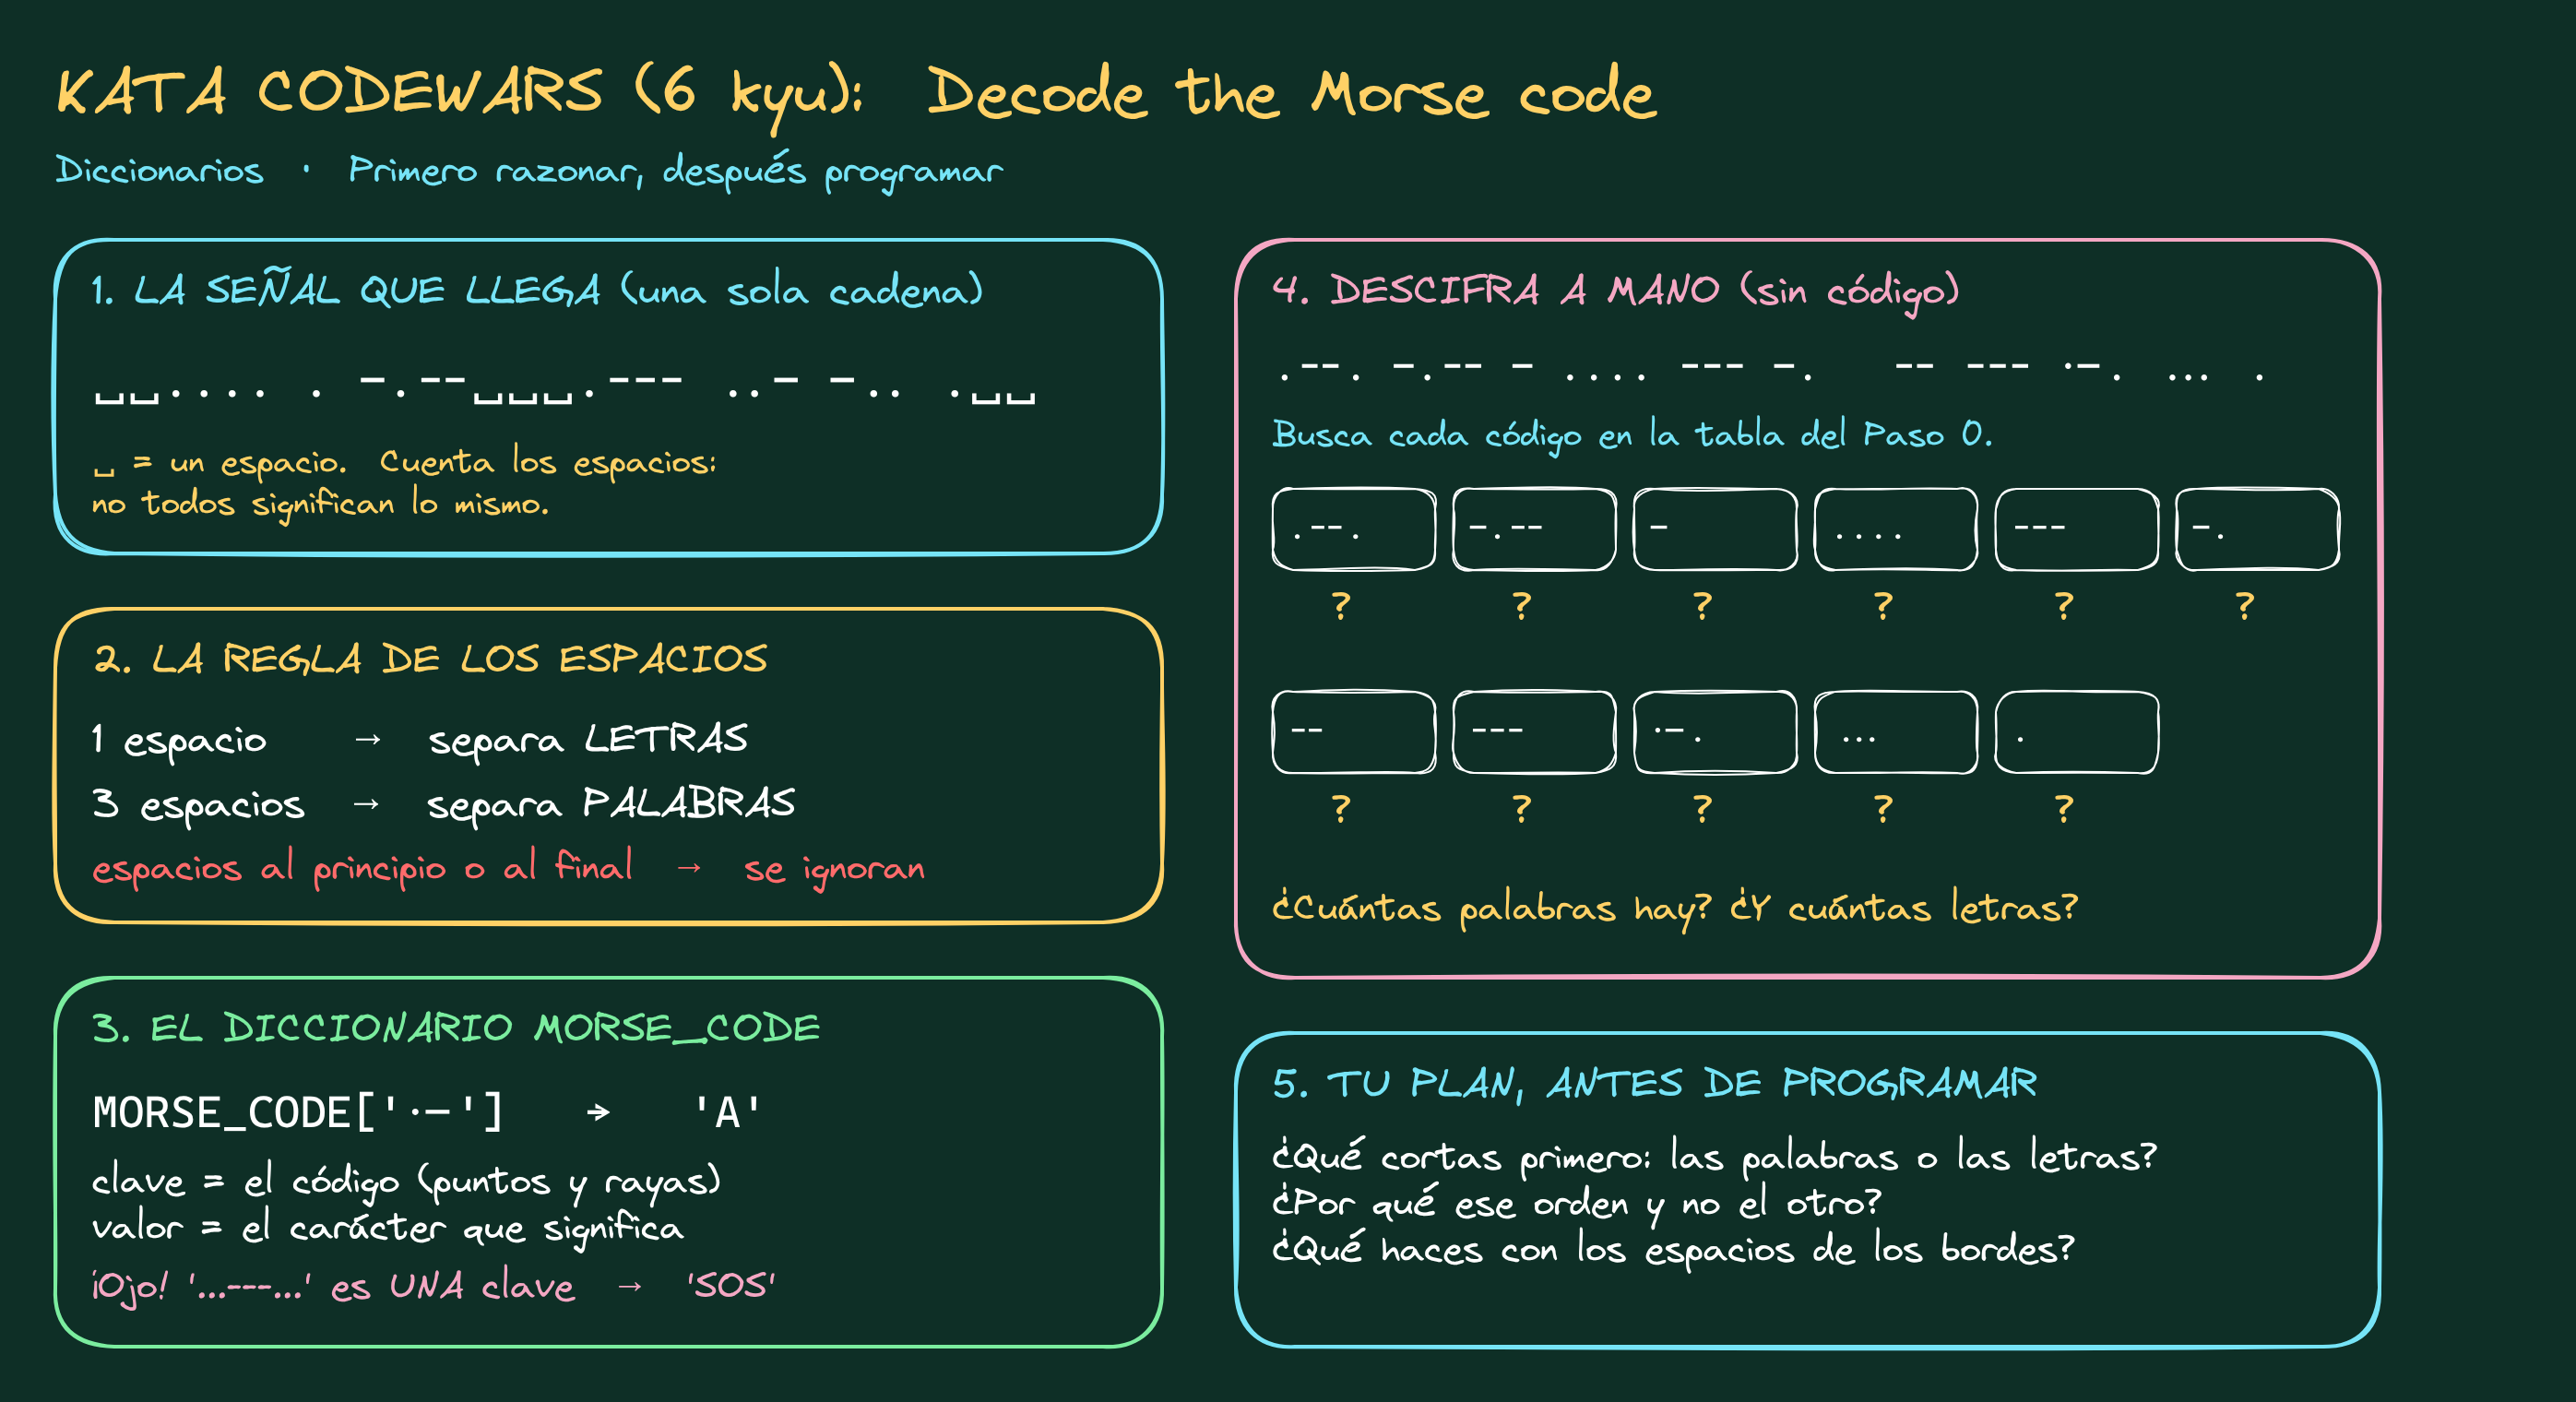

[Descargar la pizarra editable de Excalidraw](https://github.com/maximofernandezriera/katas-colab/blob/main/materiales/decode-the-morse-code-apertura.excalidraw) · Ábrela en [Excalidraw](https://excalidraw.com/) para completarla en clase.


In [ ]:
# PASO 0 — ejecuta esta celda para cargar las utilidades
# ============================================================
#  BANCO DE PRUEBAS — framework de tests estilo Codewars
#  (no hace falta modificar esta celda, solo ejecutarla)
# ============================================================
import time
import difflib
import urllib.request
import json
import traceback

def cargar_kata(slug_o_id):
    """Descarga los datos del kata desde la API pública de Codewars."""
    url = f"https://www.codewars.com/api/v1/code-challenges/{slug_o_id}"
    with urllib.request.urlopen(url) as r:
        return json.load(r)

def mostrar_kata(kata):
    from IPython.display import Markdown, display
    rank = kata.get("rank") or {}
    display(Markdown(
        f"## {kata['name']}  ·  `{rank.get('name', '?')}`\n"
        f"**Enlace:** {kata['url']}  \n"
        f"**Tags:** {', '.join(kata.get('tags', []))}\n\n---\n\n"
        + kata.get("description", "")
    ))

# ---- mini framework estilo Codewars ----
_fallos = []
_aciertos = []

def _reset():
    _fallos.clear()
    _aciertos.clear()

def describe(nombre):
    print(f"\n== {nombre} ==")

def it(nombre):
    print(f"  · {nombre}")

def assert_equals(real, esperado, msg=""):
    if real == esperado:
        _aciertos.append(1)
        print(f"    ✔ OK  →  {real!r}")
    else:
        _fallos.append((real, esperado, msg))
        print(f"    ✘ FALLO  →  obtenido {real!r}  esperado {esperado!r}  {msg}")

def resumen():
    total = len(_aciertos) + len(_fallos)
    print(f"\n{'='*40}\nResultado: {len(_aciertos)}/{total} tests superados")
    if _fallos:
        print("¡Sigue intentándolo! Revisa los fallos de arriba.")
    else:
        print("¡Todos los tests superados! 🎉 Ahora compara tu solución abajo.")

def comparar_con_referencia(mi_funcion, referencias, casos):
    """Ejecuta mi_funcion y cada función de referencia sobre 'casos'
    (lista de tuplas de argumentos) y compara resultados y tiempos."""
    for nombre, src in referencias.items():
        ns = {}
        exec(src, ns)
        ref = ns.get("solucion") or next(iter(ns.values()))
        print(f"\n### {nombre}")
        for caso in casos:
            args = caso if isinstance(caso, tuple) else (caso,)
            try:
                t0 = time.perf_counter()
                esperado = ref(*args)
                t_ref = (time.perf_counter() - t0) * 1e6
            except Exception as e:
                print(f"  referencia falla en {args}: {e}")
                continue
            try:
                t0 = time.perf_counter()
                obtenido = mi_funcion(*args)
                t_mio = (time.perf_counter() - t0) * 1e6
            except Exception:
                print(f"  tu solución lanza excepción en {args}:")
                traceback.print_exc(limit=1)
                continue
            marca = "✔" if obtenido == esperado else "✘"
            print(f"  {marca} {args} → tuyo={obtenido!r} ref={esperado!r}  "
                  f"(tú: {t_mio:.0f}µs / ref: {t_ref:.0f}µs)")

def diff(mi_src, ref_src, nombre="referencia"):
    """Muestra un diff línea a línea entre tu código y otra solución."""
    d = difflib.unified_diff(
        ref_src.splitlines(), mi_src.splitlines(),
        fromfile=nombre, tofile="tu solución", lineterm="")
    print("\n".join(d))


In [ ]:
# PASO 0 (b) — el diccionario MORSE_CODE
# En Codewars esta tabla viene precargada; aquí la creas tú al ejecutar la celda.
# Clave: el código Morse (puntos y rayas). Valor: el carácter que significa.

MORSE_CODE = {
    '.-': 'A', '-...': 'B', '-.-.': 'C', '-..': 'D', '.': 'E', '..-.': 'F',
    '--.': 'G', '....': 'H', '..': 'I', '.---': 'J', '-.-': 'K', '.-..': 'L',
    '--': 'M', '-.': 'N', '---': 'O', '.--.': 'P', '--.-': 'Q', '.-.': 'R',
    '...': 'S', '-': 'T', '..-': 'U', '...-': 'V', '.--': 'W', '-..-': 'X',
    '-.--': 'Y', '--..': 'Z', '-----': '0', '.----': '1', '..---': '2', '...--': '3',
    '....-': '4', '.....': '5', '-....': '6', '--...': '7', '---..': '8', '----.': '9',
    '.-.-.-': '.', '--..--': ',', '..--..': '?', '.----.': "'", '-.-.--': '!', '-..-.': '/',
    '-.--.': '(', '-.--.-': ')', '.-...': '&', '---...': ':', '-.-.-.': ';', '-...-': '=',
    '.-.-.': '+', '-....-': '-', '..--.-': '_', '.-..-.': '"', '...-..-': '$', '.--.-.': '@',
    '...---...': 'SOS',
}

print(f"MORSE_CODE cargado: {len(MORSE_CODE)} códigos")
print("Ejemplo  MORSE_CODE['.-']        →", repr(MORSE_CODE['.-']))
print("Ejemplo  MORSE_CODE['...---...'] →", repr(MORSE_CODE['...---...']))


In [ ]:
# PASO 1 — carga el enunciado del kata
kata = cargar_kata("decode-the-morse-code")
mostrar_kata(kata)

## Enunciado en castellano (traducción)

> Traducción al castellano del enunciado; el original en inglés se muestra en el Paso 1.

### Descifra el código Morse

> Este kata es el primero de una serie de tres sobre el código Morse. Cuando lo resuelvas puedes pasar al [siguiente](https://www.codewars.com/kata/decode-the-morse-code-advanced).

En este kata tienes que escribir un descifrador sencillo de [código Morse](https://es.wikipedia.org/wiki/C%C3%B3digo_morse). Hoy casi nadie lo usa, porque la voz y los datos digitales lo han sustituido, pero todavía se emplea en algunos sitios del mundo.

El Morse convierte cada carácter en una secuencia de «puntos» y «rayas». Por ejemplo, la letra `A` es `·−`, la `Q` es `−−·−` y el dígito `1` es `·−−−−`. No distingue mayúsculas de minúsculas; lo tradicional es usar mayúsculas.

Cuando se escribe un mensaje en Morse:

- **un espacio** separa los códigos de dos caracteres;
- **tres espacios** separan dos palabras.

Por ejemplo, el mensaje `HEY JUDE` en Morse es `···· · −·−−   ·−−− ··− −·· ·`.

**NOTA:** los espacios que sobren al principio o al final del código no significan nada y hay que ignorarlos.

Además de letras, dígitos y algunos signos de puntuación, hay códigos especiales de servicio. El más famoso es la señal internacional de socorro [SOS](https://es.wikipedia.org/wiki/SOS), que se codifica como `···−−−···`. Estos códigos especiales cuentan como **un solo carácter** y normalmente se transmiten como palabras sueltas.

**Tu tarea:** escribe una función que reciba el código Morse y devuelva el texto descifrado, legible para una persona.

```python
decode_morse('.... . -.--   .--- ..- -.. .')
# debe devolver "HEY JUDE"
```

**NOTA:** en el código tienes que usar los caracteres ASCII `.` y `-`, no los símbolos Unicode `·` y `−`.

En Codewars la tabla Morse ya viene **precargada como diccionario**: puedes usar `MORSE_CODE['.--']`. En este notebook la tienes en la celda del Paso 0.

Todas las cadenas de los tests son Morse válido, así que no hace falta comprobar errores ni excepciones.

¡Suerte!

## Hoja de ruta — lee el kata antes de programar

Rellena esto **antes** de escribir código (hay una versión imprimible en `guia-lectura-kata.html`):

1. **¿Qué recibo?** Nº de parámetros y tipos (número, texto, booleano…):
2. **¿Qué devuelvo?** ¿Número, texto, booleano? ¿El texto debe ser exacto?
3. **Ejemplo, con mis palabras:** coge un ejemplo del enunciado y explica por qué da ese resultado.
4. **Casos límite:** ¿qué pasa con 0, negativos, cadena vacía, valores iguales…?
5. **El diccionario:** ¿qué guardo como clave y qué como valor? ¿tengo que crearlo, recorrerlo o consultarlo? ¿qué pasa si una clave todavía no existe?
6. **Plan:** escribe los pasos en castellano, uno por línea, sin código.
7. **Después:** ¿mis tests cubren esos casos límite? ¿Qué aprendí?


## Laboratorio PythonTutor · las piezas sueltas

Tres experimentos pequeños, **cada uno autocontenido** (trae su propio mini diccionario). Ninguno resuelve el kata: sirven para ver cómo se comportan las piezas antes de montar tu plan. Abre el enlace, pulsa **Visualize Execution** y avanza con **Next**.

**Experimento 1 · consultar un diccionario** (clave → valor, y `in` para saber si una clave existe)

```python
morse = {'.-': 'A', '-...': 'B', '-.-.': 'C', '...---...': 'SOS'}

letra = morse['.-']
print(letra)

print('-...' in morse)
print('--' in morse)

codigo = '...---...'
print(morse[codigo])
```
▶ [Ver en PythonTutor](https://pythontutor.com/render.html#code=morse%20%3D%20%7B%27.-%27%3A%20%27A%27%2C%20%27-...%27%3A%20%27B%27%2C%20%27-.-.%27%3A%20%27C%27%2C%20%27...---...%27%3A%20%27SOS%27%7D%0A%0Aletra%20%3D%20morse%5B%27.-%27%5D%0Aprint%28letra%29%0A%0Aprint%28%27-...%27%20in%20morse%29%0Aprint%28%27--%27%20in%20morse%29%0A%0Acodigo%20%3D%20%27...---...%27%0Aprint%28morse%5Bcodigo%5D%29%0A&mode=edit&py=3)

**Experimento 2 · los espacios cuentan** (observa la lista que devuelve `split`)

```python
senal = '.- -...   -.-.'

trozos = senal.split(' ')
print(trozos)
print(len(trozos))

# ¿Por qué salen cadenas vacías ''?
# Cambia el separador ' ' de split y vuelve a visualizar:
# ¿cuál te deja justo 2 trozos?
```
▶ [Ver en PythonTutor](https://pythontutor.com/render.html#code=senal%20%3D%20%27.-%20-...%20%20%20-.-.%27%0A%0Atrozos%20%3D%20senal.split%28%27%20%27%29%0Aprint%28trozos%29%0Aprint%28len%28trozos%29%29%0A%0A%23%20%C2%BFPor%20qu%C3%A9%20salen%20cadenas%20vac%C3%ADas%20%27%27%3F%0A%23%20Cambia%20el%20separador%20%27%20%27%20de%20split%20y%20vuelve%20a%20visualizar%3A%0A%23%20%C2%BFcu%C3%A1l%20te%20deja%20justo%202%20trozos%3F%0A&mode=edit&py=3)

**Experimento 3 · limpiar los bordes y volver a unir**

```python
senal = '   .- -...  '
print(repr(senal))

limpia = senal.strip()
print(repr(limpia))

letras = ['H', 'O', 'L', 'A']
print(''.join(letras))
print('-'.join(letras))
```
▶ [Ver en PythonTutor](https://pythontutor.com/render.html#code=senal%20%3D%20%27%20%20%20.-%20-...%20%20%27%0Aprint%28repr%28senal%29%29%0A%0Alimpia%20%3D%20senal.strip%28%29%0Aprint%28repr%28limpia%29%29%0A%0Aletras%20%3D%20%5B%27H%27%2C%20%27O%27%2C%20%27L%27%2C%20%27A%27%5D%0Aprint%28%27%27.join%28letras%29%29%0Aprint%28%27-%27.join%28letras%29%29%0A&mode=edit&py=3)


## Paso 1.5 · Mi plan (modo pensar)

**Piensa antes de programar.** Rellena esta plantilla en lenguaje natural o
pseudocódigo — es parte de la entrega y tu profesor la revisará.

**ENTRADA:** ¿qué recibo? (parámetros y tipos, en mis palabras)
> …

**PLAN:** pasos numerados, cada uno empezando por verbo (*leer*, *comprobar*,
*devolver*, *calcular*…). Mínimo 3 pasos.
> 1. …
> 2. …
> 3. …

**SALIDA:** ¿qué devuelvo exactamente?
> …

**CASOS QUE VIGILO:** los casos límite que detecté en la hoja de ruta
> …


In [ ]:
# PASO 1.5 (continuación) — tu plan en formato revisable
# Escribe cada paso de tu plan como una cadena. La celda comprueba
# que el plan existe y tiene al menos 3 pasos (no corrige el contenido).

mi_plan = [
    # "1. leer ...",
    # "2. comprobar ...",
    # "3. devolver ...",
]

if not mi_plan:
    print("⚠ Tu plan está vacío: rellena la lista mi_plan con tus pasos.")
elif len(mi_plan) < 3:
    print(f"⚠ Solo {len(mi_plan)} paso(s): detalla el plan un poco más.")
else:
    print(f"✔ Plan registrado: {len(mi_plan)} pasos.")
    for paso in mi_plan:
        print("   ", paso)


In [ ]:
# PASO 2 — TU SOLUCIÓN
# La firma es la de Codewars. Usa MORSE_CODE (Paso 0 b) y tu plan del Paso 1.5.

def decode_morse(morse_code):
    raise NotImplementedError('escribe aquí tu solución')


## Escalera de ayudas (úsala solo si te atascas 15 min)

Regla: baja un peldaño por vez — Nivel 1 → Nivel 2 → Nivel 3. Nunca saltes al último sin leer el primero. Aquí solo hay pistas: el código lo escribes tú.

<details>
<summary><b>Nivel 1 — Pista de clase</b></summary>

El mensaje tiene capas, como una cebolla: el texto entero contiene **palabras** y cada palabra contiene **letras**. El diccionario solo entiende **un código de letra cada vez**. Antes de consultarlo tienes que llegar hasta la capa de las letras. ¿Por qué capa empiezas a pelar?
</details>

<details>
<summary><b>Nivel 2 — Mira cómo se trocea la señal</b></summary>

El GIF muestra los cortes en orden con el ejemplo del enunciado. Fíjate en qué pasa con los bordes y en qué hueco se corta primero. No descifra nada: las letras las sacas tú.

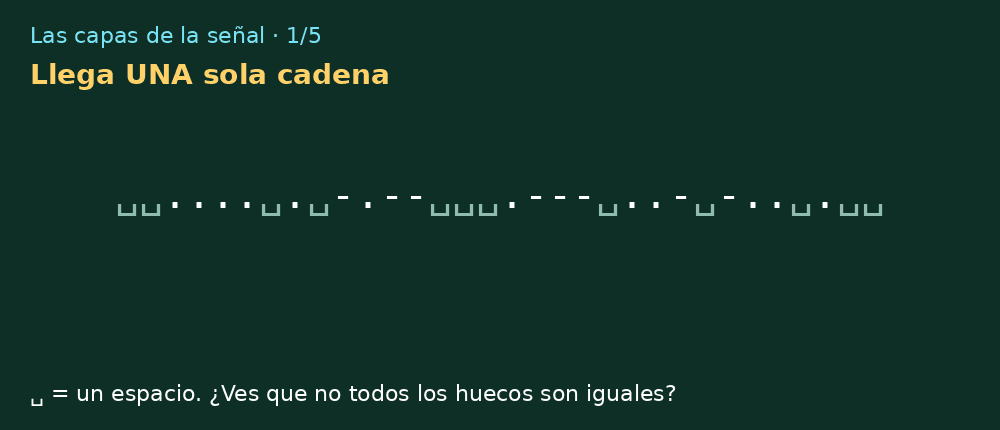
</details>

<details>
<summary><b>Nivel 3 — Las herramientas que vas a necesitar</b></summary>

- `texto.strip()` quita los espacios de los bordes.
- `texto.split(separador)` corta por **ese** separador exacto. Prueba el Experimento 2 del laboratorio con distintos separadores.
- `MORSE_CODE['.-']` traduce **un** código: la clave va entre corchetes. `'...---...'` también es un solo código.
- `''.join(lista)` y `' '.join(lista)` vuelven a pegar trozos. ¿Cuál une letras y cuál une palabras?

Pregunta de control para tu plan: si cortas por un espacio antes que por tres, ¿qué trozos raros aparecen?
</details>


In [ ]:
# PASO 3 — TUS TESTS
# Ejecuta esta celda cuando tengas decode_morse. Añade tus propios casos al final.
_reset()

def probar(entrada, esperado):
    try:
        obtenido = decode_morse(entrada)
    except NotImplementedError:
        _fallos.append((None, esperado, "sin solución"))
        print("    … todavía no has escrito decode_morse en el Paso 2")
        return
    except Exception as e:
        _fallos.append((None, esperado, repr(e)))
        print(f"    ✘ ERROR {type(e).__name__}: {e}  con la entrada {entrada!r}")
        return
    assert_equals(obtenido, esperado, f"(entrada {entrada!r})")

describe("Ejemplo del enunciado")
it("HEY JUDE")
probar('.... . -.--   .--- ..- -.. .', 'HEY JUDE')

describe("Un espacio separa letras, tres separan palabras")
it("dos letras juntas")
probar('.- -...', 'AB')
it("dos palabras de una letra")
probar('.-   -...', 'A B')

describe("Bordes")
it("una sola letra")
probar('.-', 'A')
it("espacios delante y detrás")
probar('   .... . -.--   ', 'HEY')
it("espacios solo al final")
probar('.... . -.--   ', 'HEY')

describe("SOS, dígitos y signos")
it("SOS es un único código")
probar('...---...', 'SOS')
it("SOS seguido de un signo")
probar('...---... -.-.--', 'SOS!')
it("SOS como palabra suelta")
probar('.... . .-.. .--.   ...---...', 'HELP SOS')
it("dígitos")
probar('.---- ..--- ...--', '123')

describe("Mis casos")
it("...")
# probar('...', '...')

resumen()


In [ ]:
# ============================================================
#  PASO 4 — Compara tu solución con otras
#  Tras resolver el kata en codewars.com se desbloquean las
#  soluciones de la comunidad: pégalas aquí para analizarlas.
#  Tu profesor también puede darte soluciones de referencia.
# ============================================================

# Tu código (pégalo tal cual para el diff):
mi_codigo = """
def solucion(...):
    pass  # pega aquí tu solución
"""

# Soluciones con las que comparar (nombre: código).
# Deben definir una función llamada 'solucion' (o ser la única función).
soluciones_referencia = {
    "solución del profesor": """
def solucion(...):
    pass  # solución de referencia
""",
}

# Los mismos casos de prueba de la celda anterior:
casos = [
    # (argumentos...) — rellénalos igual que en tus tests
]

# Descomenta cuando tengas algo que comparar:
# comparar_con_referencia(solucion, soluciones_referencia, casos)
# diff(mi_codigo, list(soluciones_referencia.values())[0])


---
### Cómo usar este banco de pruebas
1. **Lee el enunciado** y abre el kata en codewars.com.
2. **Escribe tu solución** en la celda correspondiente.
3. **Completa los tests**: añade casos de ejemplo del enunciado y casos límite que se te ocurran. Escribir buenos tests es parte del ejercicio.
4. **Resuelve el kata en la web** con tu solución cuando pase tus tests.
5. **Compara**: al resolverlo, Codewars desbloquea las soluciones de la comunidad. Pega las que te interesen en la última celda y analiza qué hacen distinto: ¿más cortas? ¿más rápidas? ¿más legibles? ¿por qué?
